# Deliverable C: Extended Modeling Analyses (Section 6b)
## *Rehabilitating Homeless: Dataset and Key Insights* — Critical Replication & 5 Methodological Extensions

This notebook contains the clean, well-commented, and reproducible code for **Section 6b (Modeling)** of the Data Science for Social Impact (DS4SI) Final Project. Building upon the baseline reproduction in `nochlezhka_rel_2.ipynb` (Deliverable B), we design and execute **five plausible, policy-relevant methodological extensions** to test the robustness, validity, generalizability, and algorithmic fairness of the original paper's models:

1. **Extension 1 — Eliminating Preprocessing Data Leakage (Train-Only Imputation & Scaling):** Correcting the original pipeline where mean imputation (`fillna`) and feature standardization (`StandardScaler`) were fit on the entire dataset prior to `train_test_split`.
2. **Extension 2 — Entity-Level Group Splitting by `client_id` (`GroupShuffleSplit`):** Preventing repeat clients ($6,349$ contracts across $2,754$ unique individuals, averaging $2.31$ contracts per person) from appearing in both training and validation sets simultaneously.
3. **Extension 3 — Removing Post-Hoc Target Leakage (`comments_absence` & `comments_disturbance`):** Auditing and removing social worker comment features recorded *during or at the termination of* a contract (which directly encode failure statuses `7` and `8`: client absence) to measure true *ex-ante* intake predictive performance.
4. **Extension 4 — Expanding Sample Inclusion to All Resolved Contracts (Adding Status `4` & `6`):** Re-including $1,775$ resolved contracts dropped by the original authors (`4: Partial - other` with $N=1,317$ and `6: Fail - other` with $N=458$), expanding the cohort from $N=6,349$ ($64.88\%$ success) to $N=8,124$ ($50.70\%$ success).
5. **Extension 5 — Subgroup Disaggregated Evaluation & Algorithmic Fairness Audit:** Auditing predictive performance and error rates (TPR/Recall, FPR, FNR, F1) across gender (`Male` vs. `Female`), age cohorts (`<35`, `35–54`, `55+`), housing status (`Homeless` vs. `At-risk/Housed`), and chemical addiction disclosure groups.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1000)
%matplotlib inline


---
## 0. Dataset Loading & Original Paper Baseline Reproduction
We first load `final_with_onehot_types_ALL_221120.csv` and compute the exact baseline metrics from the original paper's methodology so that every subsequent analysis can be compared **side-by-side** against the paper's reported/reproduced figures.


In [2]:
# Load full dataset
df_all = pd.read_csv('final_with_onehot_types_ALL_221120.csv')
status_map = pd.read_csv('contract_status.csv')
print(f"Full dataset shape: {df_all.shape}")
print("\nContract status distribution across the full dataset:")
status_summary = df_all.groupby(['contract_status_id', 'contract_success']).size().reset_index(name='count')
status_summary = status_summary.merge(status_map, on='contract_status_id', how='left')
status_summary[['contract_status_id', 'contract_status_description', 'contract_success', 'count']]


Full dataset shape: (8532, 100)

Contract status distribution across the full dataset:
Out[2]: 
   contract_status_id contract_status_description  contract_success  count
0                   1                 In progress                 0    408
1                   2                   Completed                 1   4119
2                   3  Partial - client rejection                 0    276
3                   4             Partial - other                 0   1317
4                   5     Fail - client rejection                 0    138
5                   6                Fail - other                 0    458
6                   7    Partial - client absence                 0   1003
7                   8                         NaN                 0    813


,contract_status_id,contract_status_description,contract_success,count
0,1,In progress,0,408
1,2,Completed,1,4119
2,3,Partial - client rejection,0,276
3,4,Partial - other,0,1317
4,5,Fail - client rejection,0,138
5,6,Fail - other,0,458
6,7,Partial - client absence,0,1003
7,8,NaN,0,813


In [3]:
# Original paper subset: only status IDs in [2, 3, 5, 7, 8]
subset = df_all[df_all.contract_status_id.isin([2, 3, 5, 7, 8])].copy()
x_columns = [c for c in subset.columns if c not in ['contract_id', 'client_id', 'contract_success', 'contract_status_id']]

zero_columns = [
    'comments_pregnancy', 'comments_ticket', 'comments_disturbance', 'comments_disease',
    'comments_divorce', 'comments_illiteracy', 'comments_fire', 'comments_disability',
    'comments_foreigner', 'comments_mental', 'comments_chem', 'comments_absence',
    'comments_aggression', 'comments_noresidence', 'comments_death', 'comments_relatives',
    'comments_alcohol', 'comments_orphange', 'comments_court', 'comments_confinement',
    'comments_nursinghome', 'comments_work', 'comments_social_benefits',
    'source_temp_job', 'source_relatives', 'source_charity', 'source_other',
    'source_alms', 'source_gathering', 'source_perm_job', 'source_rehabs',
    'chem_noanswer', 'chem_confirmed', 'chem_no', 'chem_possible', 'disability_group'
]
nan_columns = subset[x_columns].columns[subset[x_columns].isna().any()].tolist()
rest_columns = [c for c in nan_columns if c not in zero_columns]

# Helper function to compute evaluation metrics consistently (matching paper's convention and standard convention)
def compute_metrics(y_true, y_pred, y_prob=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (Pos)': precision_score(y_true, y_pred, zero_division=0),
        'Recall / TPR': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'Paper Precision (recall_pos)': precision_score(y_pred, y_true, zero_division=0),
        'Paper Recall (prec_pos)': recall_score(y_pred, y_true, zero_division=0),
        'FPR': fp / (fp + tn) if (fp + tn) > 0 else np.nan,
        'FNR': fn / (fn + tp) if (fn + tp) > 0 else np.nan,
        'ROC-AUC': roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan
    }

# Paper's exact hyperparameters for XGBoost
xgb_under_params = {'eta': 0.47, 'max_depth': 13, 'n_estimators': 686, 'random_state': SEED, 'tree_method': 'exact'}
xgb_over_params  = {'eta': 0.34, 'max_depth': 9,  'n_estimators': 853, 'random_state': SEED, 'tree_method': 'exact'}
print(f"Paper subset: {len(subset)} contracts across {subset['client_id'].nunique()} unique clients ({len(x_columns)} features).")


Paper subset: 6349 contracts across 2754 unique clients (96 features).


---
## Extension 1: Eliminating Preprocessing Data Leakage (Train-Only Imputation & Scaling)

### Hypothesis & Rationale
In `nochlezhka_rel_2.ipynb` (Cells 39–46), the authors performed missing-value imputation (`X_t[rest].fillna(X_t[rest].mean())`) and standardization (`StandardScaler().fit_transform(X_nonans)`) on the **entire dataset `X_t` before splitting** into training and validation sets (`train_test_split`). This introduces classic **preprocessing data leakage**: validation distribution statistics (means and variances) leak into training feature representations.

Here, we implement a **strictly leak-free preprocessing pipeline** where imputation means and `StandardScaler` parameters are estimated **exclusively on the training set** (`X_train`) and subsequently applied to `X_val`, and compare all models side-by-side against the paper's leaked pipeline.


In [4]:
# 1A. Paper's Leaked Pipeline (fit on full X_t before split)
X_t = subset[x_columns].copy()
y_t = subset['contract_success'].copy()

X_leaked = X_t.copy()
X_leaked[zero_columns] = X_leaked[zero_columns].fillna(0)
X_leaked[rest_columns] = X_leaked[rest_columns].fillna(X_leaked[rest_columns].mean())
sc_leaked = StandardScaler()
X_std_leaked = sc_leaked.fit_transform(X_leaked)

X_tr_leak, X_val_leak, y_tr_leak, y_val_leak = train_test_split(
    X_std_leaked, y_t, test_size=0.2, random_state=SEED, stratify=y_t
)

# 1B. Leak-Free Pipeline (split FIRST, then fit imputer & scaler ONLY on X_train)
X_tr_raw, X_val_raw, y_tr_clean, y_val_clean = train_test_split(
    X_t, y_t, test_size=0.2, random_state=SEED, stratify=y_t
)

train_means = X_tr_raw[rest_columns].mean()
X_tr_imp = X_tr_raw.copy()
X_val_imp = X_val_raw.copy()

X_tr_imp[zero_columns] = X_tr_imp[zero_columns].fillna(0)
X_tr_imp[rest_columns] = X_tr_imp[rest_columns].fillna(train_means)

X_val_imp[zero_columns] = X_val_imp[zero_columns].fillna(0)
X_val_imp[rest_columns] = X_val_imp[rest_columns].fillna(train_means) # Strictly using training means

sc_clean = StandardScaler()
X_tr_std_clean = sc_clean.fit_transform(X_tr_imp)
X_val_std_clean = sc_clean.transform(X_val_imp)

# Compare across all classical models that rely on imputed + scaled data
models_spec = [
    ('Logistic Regression', lambda: LogisticRegression(random_state=SEED)),
    ('SVM (Linear)',        lambda: SVC(kernel='linear', probability=True, random_state=SEED)),
    ('Decision Tree',       lambda: DecisionTreeClassifier(random_state=SEED)),
    ('k-NN',                lambda: KNeighborsClassifier()),
    ('Random Forest',       lambda: RandomForestClassifier(random_state=SEED)),
]

ext1_rows = []
for model_name, model_fn in models_spec:
    for samp_name, SamplerCls in [('Undersampling', RandomUnderSampler), ('Oversampling', RandomOverSampler)]:
        # Paper Leaked
        samp_l = SamplerCls(random_state=SEED)
        X_res_l, y_res_l = samp_l.fit_resample(X_tr_leak, y_tr_leak)
        clf_l = model_fn()
        clf_l.fit(X_res_l, y_res_l)
        pred_l = clf_l.predict(X_val_leak)
        m_l = compute_metrics(y_val_leak, pred_l)

        # Leak-Free
        samp_c = SamplerCls(random_state=SEED)
        X_res_c, y_res_c = samp_c.fit_resample(X_tr_std_clean, y_tr_clean)
        clf_c = model_fn()
        clf_c.fit(X_res_c, y_res_c)
        pred_c = clf_c.predict(X_val_std_clean)
        m_c = compute_metrics(y_val_clean, pred_c)

        ext1_rows.append({
            'Model': model_name,
            'Sampling': samp_name,
            'Leaked Acc': round(m_l['Accuracy'], 4),
            'Leak-Free Acc': round(m_c['Accuracy'], 4),
            'Leaked F1': round(m_l['F1 Score'], 4),
            'Leak-Free F1': round(m_c['F1 Score'], 4),
            'Delta F1': round(m_c['F1 Score'] - m_l['F1 Score'], 4)
        })

ext1_df = pd.DataFrame(ext1_rows)
print("=== Extension 1: Side-by-Side Comparison (Paper Leaked vs. Leak-Free Preprocessing) ===")
ext1_df


=== Extension 1: Side-by-Side Comparison (Paper Leaked vs. Leak-Free Preprocessing) ===
Out[4]: 
                 Model       Sampling  Leaked Acc  Leak-Free Acc  Leaked F1  Leak-Free F1  Delta F1
0  Logistic Regression  Undersampling      0.6346         0.6339     0.6903        0.6894   -0.0009
1  Logistic Regression   Oversampling      0.6370         0.6370     0.6916        0.6916    0.0000
2         SVM (Linear)  Undersampling      0.6378         0.6362     0.6933        0.6916   -0.0017
3         SVM (Linear)   Oversampling      0.6315         0.6323     0.6781        0.6790    0.0009
4        Decision Tree  Undersampling      0.7228         0.7228     0.7714        0.7714    0.0000
5        Decision Tree   Oversampling      0.7693         0.7693     0.8165        0.8165    0.0000
6                 k-NN  Undersampling      0.6346         0.6339     0.6848        0.6847   -0.0000
7                 k-NN   Oversampling      0.6449         0.6433     0.7003        0.6982   -0.0021
8  

,Model,Sampling,Leaked Acc,Leak-Free Acc,Leaked F1,Leak-Free F1,Delta F1
0,Logistic Regression,Undersampling,0.6346,0.6339,0.6903,0.6894,-0.0009
1,Logistic Regression,Oversampling,0.6370,0.6370,0.6916,0.6916,0.0000
2,SVM (Linear),Undersampling,0.6378,0.6362,0.6933,0.6916,-0.0017
3,SVM (Linear),Oversampling,0.6315,0.6323,0.6781,0.6790,0.0009
4,Decision Tree,Undersampling,0.7228,0.7228,0.7714,0.7714,0.0000
5,Decision Tree,Oversampling,0.7693,0.7693,0.8165,0.8165,0.0000
6,k-NN,Undersampling,0.6346,0.6339,0.6848,0.6847,-0.0000
7,k-NN,Oversampling,0.6449,0.6433,0.7003,0.6982,-0.0021
8,Random Forest,Undersampling,0.7709,0.7709,0.8094,0.8094,0.0000
9,Random Forest,Oversampling,0.8142,0.8157,0.8571,0.8584,0.0012


---
## Extension 2: Entity-Level Group Splitting by `client_id` (`GroupShuffleSplit`)

### Hypothesis & Rationale
In the paper's dataset ($N=6,349$ contracts), there are only $2,754$ unique clients (`client_id`), meaning clients sign an average of **$2.31$ contracts** (with some clients signing over 10 contracts). Because the original paper performed a standard contract-level `train_test_split`, **the exact same individual frequently appears in both the training set and the validation set**. High-capacity tree ensembles (`RandomForest`, `XGBoost`, `CatBoost`) can memorize unique combinations of static client attributes (`age`, `gender`, `from_orphanage`, `was_confined`, comment histories) and achieve artificially inflated validation accuracy.

Here, we first quantify the exact client overlap in the paper's split, and then evaluate models under a strict **Entity-Level Group Split (`GroupShuffleSplit` on `client_id`)** where zero clients overlap between training and validation sets.


In [5]:
# Quantify client overlap in the original paper's split
train_idx_orig, val_idx_orig = train_test_split(
    subset.index, test_size=0.2, random_state=SEED, stratify=subset['contract_success']
)
train_clients_orig = set(subset.loc[train_idx_orig, 'client_id'])
val_clients_orig = set(subset.loc[val_idx_orig, 'client_id'])
overlap_clients = train_clients_orig.intersection(val_clients_orig)
overlap_val_contracts = subset.loc[val_idx_orig, 'client_id'].isin(overlap_clients).sum()

print(f"Original Paper Split Client Overlap Audit:")
print(f"  - Unique clients in validation set: {len(val_clients_orig)}")
print(f"  - Validation clients ALSO present in training set: {len(overlap_clients)} ({len(overlap_clients)/len(val_clients_orig)*100:.2f}%)")
print(f"  - Validation contracts belonging to leaked training clients: {overlap_val_contracts} / {len(val_idx_orig)} ({overlap_val_contracts/len(val_idx_orig)*100:.2f}%)")

# Perform GroupShuffleSplit by client_id (0% client overlap)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
grp_tr_idx, grp_val_idx = next(gss.split(X_t, y_t, groups=subset['client_id']))

X_tr_grp, X_val_grp = X_t.iloc[grp_tr_idx], X_t.iloc[grp_val_idx]
y_tr_grp, y_val_grp = y_t.iloc[grp_tr_idx], y_t.iloc[grp_val_idx]

assert len(set(subset.iloc[grp_tr_idx]['client_id']).intersection(set(subset.iloc[grp_val_idx]['client_id']))) == 0
print(f"\nGroupShuffleSplit verified: 0 overlapping clients! Train contracts: {len(X_tr_grp)}, Val contracts: {len(X_val_grp)}")


Original Paper Split Client Overlap Audit:
  - Unique clients in validation set: 954
  - Validation clients ALSO present in training set: 656 (68.76%)
  - Validation contracts belonging to leaked training clients: 934 / 1270 (73.54%)

GroupShuffleSplit verified: 0 overlapping clients! Train contracts: 5111, Val contracts: 1238


In [6]:
# Leak-free imputation & scaling for GroupShuffleSplit
grp_means = X_tr_grp[rest_columns].mean()
X_tr_grp_imp = X_tr_grp.copy()
X_val_grp_imp = X_val_grp.copy()
X_tr_grp_imp[zero_columns] = X_tr_grp_imp[zero_columns].fillna(0)
X_tr_grp_imp[rest_columns] = X_tr_grp_imp[rest_columns].fillna(grp_means)
X_val_grp_imp[zero_columns] = X_val_grp_imp[zero_columns].fillna(0)
X_val_grp_imp[rest_columns] = X_val_grp_imp[rest_columns].fillna(grp_means)

sc_grp = StandardScaler()
X_tr_grp_std = sc_grp.fit_transform(X_tr_grp_imp)
X_val_grp_std = sc_grp.transform(X_val_grp_imp)

# Evaluate key models on Paper Row-Split vs. Client Group-Split
ext2_rows = []

for samp_name, SamplerCls in [('Undersampling', RandomUnderSampler), ('Oversampling', RandomOverSampler)]:
    # 1. Logistic Regression
    s1 = SamplerCls(random_state=SEED)
    X_r1, y_r1 = s1.fit_resample(X_tr_std_clean, y_tr_clean)
    lr_row = LogisticRegression(random_state=SEED).fit(X_r1, y_r1)
    m_lr_row = compute_metrics(y_val_clean, lr_row.predict(X_val_std_clean))

    s2 = SamplerCls(random_state=SEED)
    X_r2, y_r2 = s2.fit_resample(X_tr_grp_std, y_tr_grp)
    lr_grp = LogisticRegression(random_state=SEED).fit(X_r2, y_r2)
    m_lr_grp = compute_metrics(y_val_grp, lr_grp.predict(X_val_grp_std))

    ext2_rows.append({
        'Model': 'Logistic Regression', 'Sampling': samp_name,
        'Paper Row-Split Acc': round(m_lr_row['Accuracy'], 4), 'Client Group-Split Acc': round(m_lr_grp['Accuracy'], 4),
        'Paper Row-Split F1': round(m_lr_row['F1 Score'], 4),   'Client Group-Split F1': round(m_lr_grp['F1 Score'], 4),
        'Delta Acc': round(m_lr_grp['Accuracy'] - m_lr_row['Accuracy'], 4),
        'Delta F1': round(m_lr_grp['F1 Score'] - m_lr_row['F1 Score'], 4)
    })

    # 2. Random Forest
    rf_row = RandomForestClassifier(random_state=SEED).fit(X_r1, y_r1)
    m_rf_row = compute_metrics(y_val_clean, rf_row.predict(X_val_std_clean))

    rf_grp = RandomForestClassifier(random_state=SEED).fit(X_r2, y_r2)
    m_rf_grp = compute_metrics(y_val_grp, rf_grp.predict(X_val_grp_std))

    ext2_rows.append({
        'Model': 'Random Forest', 'Sampling': samp_name,
        'Paper Row-Split Acc': round(m_rf_row['Accuracy'], 4), 'Client Group-Split Acc': round(m_rf_grp['Accuracy'], 4),
        'Paper Row-Split F1': round(m_rf_row['F1 Score'], 4),   'Client Group-Split F1': round(m_rf_grp['F1 Score'], 4),
        'Delta Acc': round(m_rf_grp['Accuracy'] - m_rf_row['Accuracy'], 4),
        'Delta F1': round(m_rf_grp['F1 Score'] - m_rf_row['F1 Score'], 4)
    })

    # 3. XGBoost (on native NaNs)
    s_raw1 = SamplerCls(random_state=SEED)
    X_rt1, y_rt1 = s_raw1.fit_resample(X_tr_raw, y_tr_clean)
    xgb_p = xgb_under_params if samp_name == 'Undersampling' else xgb_over_params
    xgb_row = XGBClassifier(**xgb_p).fit(X_rt1, y_rt1)
    m_xgb_row = compute_metrics(y_val_clean, xgb_row.predict(X_val_raw))

    s_raw2 = SamplerCls(random_state=SEED)
    X_rt2, y_rt2 = s_raw2.fit_resample(X_tr_grp, y_tr_grp)
    xgb_grp = XGBClassifier(**xgb_p).fit(X_rt2, y_rt2)
    m_xgb_grp = compute_metrics(y_val_grp, xgb_grp.predict(X_val_grp))

    ext2_rows.append({
        'Model': 'XGBoost', 'Sampling': samp_name,
        'Paper Row-Split Acc': round(m_xgb_row['Accuracy'], 4), 'Client Group-Split Acc': round(m_xgb_grp['Accuracy'], 4),
        'Paper Row-Split F1': round(m_xgb_row['F1 Score'], 4),   'Client Group-Split F1': round(m_xgb_grp['F1 Score'], 4),
        'Delta Acc': round(m_xgb_grp['Accuracy'] - m_xgb_row['Accuracy'], 4),
        'Delta F1': round(m_xgb_grp['F1 Score'] - m_xgb_row['F1 Score'], 4)
    })

    # 4. CatBoost (on native NaNs)
    cb_row = CatBoostClassifier(random_state=SEED, verbose=0).fit(X_rt1, y_rt1)
    m_cb_row = compute_metrics(y_val_clean, cb_row.predict(X_val_raw))

    cb_grp = CatBoostClassifier(random_state=SEED, verbose=0).fit(X_rt2, y_rt2)
    m_cb_grp = compute_metrics(y_val_grp, cb_grp.predict(X_val_grp))

    ext2_rows.append({
        'Model': 'CatBoost', 'Sampling': samp_name,
        'Paper Row-Split Acc': round(m_cb_row['Accuracy'], 4), 'Client Group-Split Acc': round(m_cb_grp['Accuracy'], 4),
        'Paper Row-Split F1': round(m_cb_row['F1 Score'], 4),   'Client Group-Split F1': round(m_cb_grp['F1 Score'], 4),
        'Delta Acc': round(m_cb_grp['Accuracy'] - m_cb_row['Accuracy'], 4),
        'Delta F1': round(m_cb_grp['F1 Score'] - m_cb_row['F1 Score'], 4)
    })

ext2_df = pd.DataFrame(ext2_rows)
print("=== Extension 2: Side-by-Side Comparison (Paper Row-Split vs. Client-Level GroupShuffleSplit) ===")
ext2_df


=== Extension 2: Side-by-Side Comparison (Paper Row-Split vs. Client-Level GroupShuffleSplit) ===
Out[6]: 
                 Model       Sampling  Paper Row-Split Acc  Client Group-Split Acc  Paper Row-Split F1  Client Group-Split F1  Delta Acc  Delta F1
0  Logistic Regression  Undersampling               0.6339                  0.6341              0.6894                 0.7002     0.0002    0.0108
1        Random Forest  Undersampling               0.7709                  0.6527              0.8094                 0.7336    -0.1182   -0.0758
2              XGBoost  Undersampling               0.7937                  0.6745              0.8301                 0.7538    -0.1192   -0.0763
3             CatBoost  Undersampling               0.7551                  0.6607              0.7955                 0.7348    -0.0944   -0.0607
4  Logistic Regression   Oversampling               0.6370                  0.6341              0.6916                 0.7010    -0.0029    0.0094
5        Ra

,Model,Sampling,Paper Row-Split Acc,Client Group-Split Acc,Paper Row-Split F1,Client Group-Split F1,Delta Acc,Delta F1
0,Logistic Regression,Undersampling,0.6339,0.6341,0.6894,0.7002,0.0002,0.0108
1,Random Forest,Undersampling,0.7709,0.6527,0.8094,0.7336,-0.1182,-0.0758
2,XGBoost,Undersampling,0.7937,0.6745,0.8301,0.7538,-0.1192,-0.0763
3,CatBoost,Undersampling,0.7551,0.6607,0.7955,0.7348,-0.0944,-0.0607
4,Logistic Regression,Oversampling,0.6370,0.6341,0.6916,0.7010,-0.0029,0.0094
5,Random Forest,Oversampling,0.8157,0.6971,0.8584,0.7902,-0.1187,-0.0682
6,XGBoost,Oversampling,0.8339,0.6785,0.8713,0.7694,-0.1553,-0.1019
7,CatBoost,Oversampling,0.7827,0.6696,0.8266,0.7520,-0.1130,-0.0747


In [7]:
# Breakdown of validation accuracy on Seen Clients vs. Unseen Clients in the Paper's Original Split
seen_mask = subset.loc[val_idx_orig, 'client_id'].isin(overlap_clients).values
s_over = RandomOverSampler(random_state=SEED)
X_rt_over, y_rt_over = s_over.fit_resample(X_tr_raw, y_tr_clean)
xgb_baseline_over = XGBClassifier(**xgb_over_params).fit(X_rt_over, y_rt_over)
val_preds_orig = xgb_baseline_over.predict(X_val_raw)

acc_seen = accuracy_score(y_val_clean[seen_mask], val_preds_orig[seen_mask])
acc_unseen = accuracy_score(y_val_clean[~seen_mask], val_preds_orig[~seen_mask])
f1_seen = f1_score(y_val_clean[seen_mask], val_preds_orig[seen_mask])
f1_unseen = f1_score(y_val_clean[~seen_mask], val_preds_orig[~seen_mask])

print(f"XGBoost (Oversampled) Performance Disaggregation inside Original Validation Set:")
print(f"  - Leaked/Seen Clients (in Train & Val, n={seen_mask.sum()}):   Accuracy = {acc_seen:.4f}, F1 = {f1_seen:.4f}")
print(f"  - Truly Unseen Clients (only in Val, n={(~seen_mask).sum()}): Accuracy = {acc_unseen:.4f}, F1 = {f1_unseen:.4f}")
print(f"  - Memorization Gap (Seen - Unseen):                    +{acc_seen - acc_unseen:.4f} Accuracy (+{f1_seen - f1_unseen:.4f} F1)")


XGBoost (Oversampled) Performance Disaggregation inside Original Validation Set:
  - Leaked/Seen Clients (in Train & Val, n=934):   Accuracy = 0.8887, F1 = 0.9105
  - Truly Unseen Clients (only in Val, n=336): Accuracy = 0.6815, F1 = 0.7757
  - Memorization Gap (Seen - Unseen):                    +0.2071 Accuracy (+0.1348 F1)


---
## Extension 3: Removing Post-Hoc Target Leakage Features (`comments_absence` & `comments_disturbance`)

### Hypothesis & Rationale
In the original paper's feature importance plots for Logistic Regression, SVM, Decision Tree, Random Forest, and CatBoost, `Comments: absence` (`comments_absence`) consistently ranks among the top negative predictors of contract success. However, inspecting the contract status definitions reveals a severe **temporal / target leakage flaw**:
* Unsuccessful contracts in `subset` are primarily composed of status `7` (`Partial - client absence`, $N=1,003$) and status `8` (`Fail - client absence`, $N=813$), which together account for **$81.4\%$ ($1,816 / 2,230$) of all unsuccessful contracts**.
* The binary feature `comments_absence` is extracted from free-text case notes where the social worker wrote that the client failed to show up or disappeared *during the contract period*. Similarly, `comments_disturbance` records rule violations during shelter stays.

When deploying a model at **contract intake** (when a social contract is first signed), future absences or rule disturbances have not yet occurred. Below, we audit the empirical correlation between `comments_absence` and contract failure, and re-evaluate the models after removing post-hoc process features (`comments_absence` and `comments_disturbance`), both under the row split and combined with the `client_id` group split.


In [8]:
# Audit empirical relationship between comments_absence and contract_status_id
absence_audit = subset.groupby('contract_status_id')['comments_absence'].agg(['count', 'mean']).reset_index()
absence_audit = absence_audit.merge(status_map, on='contract_status_id', how='left')
absence_audit['absence_rate_%'] = (absence_audit['mean'] * 100).round(2)
print("Rate of `comments_absence == 1` across Contract Statuses:")
print(absence_audit[['contract_status_id', 'contract_status_description', 'count', 'absence_rate_%']].to_string(index=False))

posthoc_cols = ['comments_absence', 'comments_disturbance']
x_cols_noleak = [c for c in x_columns if c not in posthoc_cols]

ext3_rows = []
for split_label, (X_tr_cur, X_val_cur, y_tr_cur, y_val_cur) in [
    ('Paper Row Split', (X_tr_raw, X_val_raw, y_tr_clean, y_val_clean)),
    ('Client Group Split', (X_tr_grp, X_val_grp, y_tr_grp, y_val_grp))
]:
    for feat_label, cols_use in [
        ('All 96 Features (With Post-Hoc Leakage)', x_columns),
        ('Ex-Ante 94 Features (No Absence/Disturbance)', x_cols_noleak)
    ]:
        # Prepare scaled versions for LR/RF and raw versions for XGB/CatBoost
        rest_cur = [c for c in rest_columns if c in cols_use]
        zero_cur = [c for c in zero_columns if c in cols_use]
        means_cur = X_tr_cur[rest_cur].mean()

        X_tr_i = X_tr_cur[cols_use].copy()
        X_val_i = X_val_cur[cols_use].copy()
        X_tr_i[zero_cur] = X_tr_i[zero_cur].fillna(0)
        X_tr_i[rest_cur] = X_tr_i[rest_cur].fillna(means_cur)
        X_val_i[zero_cur] = X_val_i[zero_cur].fillna(0)
        X_val_i[rest_cur] = X_val_i[rest_cur].fillna(means_cur)

        sc_cur = StandardScaler()
        X_tr_s = sc_cur.fit_transform(X_tr_i)
        X_val_s = sc_cur.transform(X_val_i)

        ros_s = RandomOverSampler(random_state=SEED)
        X_res_s, y_res_s = ros_s.fit_resample(X_tr_s, y_tr_cur)

        ros_r = RandomOverSampler(random_state=SEED)
        X_res_r, y_res_r = ros_r.fit_resample(X_tr_cur[cols_use], y_tr_cur)

        # Models (Oversampling)
        lr_m = LogisticRegression(random_state=SEED).fit(X_res_s, y_res_s)
        rf_m = RandomForestClassifier(random_state=SEED).fit(X_res_s, y_res_s)
        xgb_m = XGBClassifier(**xgb_over_params).fit(X_res_r, y_res_r)
        cb_m = CatBoostClassifier(random_state=SEED, verbose=0).fit(X_res_r, y_res_r)

        for m_name, pred in [
            ('Logistic Regression (OS)', lr_m.predict(X_val_s)),
            ('Random Forest (OS)',       rf_m.predict(X_val_s)),
            ('XGBoost (OS)',             xgb_m.predict(X_val_cur[cols_use])),
            ('CatBoost (OS)',            cb_m.predict(X_val_cur[cols_use]))
        ]:
            met = compute_metrics(y_val_cur, pred)
            ext3_rows.append({
                'Split Design': split_label,
                'Feature Set': feat_label,
                'Model': m_name,
                'Accuracy': round(met['Accuracy'], 4),
                'Precision': round(met['Precision (Pos)'], 4),
                'Recall': round(met['Recall / TPR'], 4),
                'F1 Score': round(met['F1 Score'], 4)
            })

ext3_df = pd.DataFrame(ext3_rows)
ext3_pivot = ext3_df.pivot(index=['Split Design', 'Model'], columns='Feature Set', values=['Accuracy', 'F1 Score'])
print("=== Extension 3: Impact of Removing Post-Hoc Leakage Features (`comments_absence`, `comments_disturbance`) ===")
ext3_pivot


Rate of `comments_absence == 1` across Contract Statuses:
 contract_status_id contract_status_description  count  absence_rate_%
                  2                   Completed   3986            1.73
                  3  Partial - client rejection    272            1.84
                  5     Fail - client rejection    128            2.34
                  7    Partial - client absence    933            5.57
                  8                         NaN    774            8.14
=== Extension 3: Impact of Removing Post-Hoc Leakage Features (`comments_absence`, `comments_disturbance`) ===
Out[8]: 
                                                                           Accuracy                                                                             F1 Score                                             
Feature Set                                 All 96 Features (With Post-Hoc Leakage) Ex-Ante 94 Features (No Absence/Disturbance) All 96 Features (With Post-Hoc Leakage) Ex-Ante 94 Fe

Accuracy                                                                             F1 Score                                             
Feature Set                                 All 96 Features (With Post-Hoc Leakage) Ex-Ante 94 Features (No Absence/Disturbance) All 96 Features (With Post-Hoc Leakage) Ex-Ante 94 Features (No Absence/Disturbance)
Split Design       Model                                                                                                                                                                                             
Client Group Split CatBoost (OS)                                             0.6696                                       0.6753                                  0.7520                                       0.7590
                   Logistic Regression (OS)                                  0.6341                                       0.6268                                  0.7010                                       0.6948
                   Random Forest (OS)                                        0.6971                                       0.6834                                  0.7902                                       0.7775
                   XGBoost (OS)                                              0.6785                                       0.6672                                  0.7694                                       0.7632
Paper Row Split    CatBoost (OS)                                             0.7827                                       0.7866                                  0.8266                                       0.8286
                   Logistic Regression (OS)                                  0.6370                                       0.6299                                  0.6916                                       0.6850
                   Random Forest (OS)                                        0.8157                                       0.8150                                  0.8584                                       0.8582
                   XGBoost (OS)                                              0.8339                                       0.8409                                  0.8713                                       0.8771

---
## Extension 4: Expanding Sample Inclusion to All Resolved Contracts (Including Status `4` & `6`)

### Hypothesis & Rationale
The original authors restricted their analysis to `contract_status_id in [2, 3, 5, 7, 8]` ($N=6,349$), explicitly **excluding $1,775$ resolved contracts** classified under:
* `contract_status_id == 4` (`Partial - other`, $N=1,317$, `contract_success = 0`)
* `contract_status_id == 6` (`Fail - other`, $N=458$, `contract_success = 0`)

While excluding `1: In progress` ($N=408$) is methodologically necessary because outcomes are right-censored, excluding `4` and `6` removes **$44.3\%$ ($1,775 / 4,005$) of all non-completed contracts**—specifically the grey-zone cases where contracts failed due to institutional bottlenecks, external bureaucratic delays, hospitalization, or complex multi-factor barriers rather than explicit client rejection or absence.

Here, we re-run the modeling suite on the **Full Resolved Cohort ($N=8,124$, statuses `2, 3, 4, 5, 6, 7, 8`)**, where the true completion rate is **$50.70\%$** (rather than the artificially inflated $64.88\%$ in the paper's subset).


In [9]:
# Construct Full Resolved Cohort (all statuses except 1: In progress)
full_resolved = df_all[df_all.contract_status_id != 1].copy()
X_full = full_resolved[x_columns].copy()
y_full = full_resolved['contract_success'].copy()

print(f"Paper Curated Subset: N = {len(subset)} | Success Rate = {subset['contract_success'].mean()*100:.2f}%")
print(f"Full Resolved Cohort: N = {len(full_resolved)} | Success Rate = {full_resolved['contract_success'].mean()*100:.2f}%")

# Train/Val Split on Full Resolved Cohort (Leak-Free)
X_tr_f, X_val_f, y_tr_f, y_val_f = train_test_split(
    X_full, y_full, test_size=0.2, random_state=SEED, stratify=y_full
)

f_means = X_tr_f[rest_columns].mean()
X_tr_f_imp = X_tr_f.copy()
X_val_f_imp = X_val_f.copy()
X_tr_f_imp[zero_columns] = X_tr_f_imp[zero_columns].fillna(0)
X_tr_f_imp[rest_columns] = X_tr_f_imp[rest_columns].fillna(f_means)
X_val_f_imp[zero_columns] = X_val_f_imp[zero_columns].fillna(0)
X_val_f_imp[rest_columns] = X_val_f_imp[rest_columns].fillna(f_means)

sc_f = StandardScaler()
X_tr_f_std = sc_f.fit_transform(X_tr_f_imp)
X_val_f_std = sc_f.transform(X_val_f_imp)

ext4_rows = []
for samp_name, SamplerCls in [('Undersampling', RandomUnderSampler), ('Oversampling', RandomOverSampler)]:
    # Resample Paper Subset vs Full Resolved Cohort
    s_sub_std = SamplerCls(random_state=SEED)
    X_rs_sub, y_rs_sub = s_sub_std.fit_resample(X_tr_std_clean, y_tr_clean)
    s_sub_raw = SamplerCls(random_state=SEED)
    X_rr_sub, y_rr_sub = s_sub_raw.fit_resample(X_tr_raw, y_tr_clean)

    s_ful_std = SamplerCls(random_state=SEED)
    X_rs_ful, y_rs_ful = s_ful_std.fit_resample(X_tr_f_std, y_tr_f)
    s_ful_raw = SamplerCls(random_state=SEED)
    X_rr_ful, y_rr_ful = s_ful_raw.fit_resample(X_tr_f, y_tr_f)

    xgb_p = xgb_under_params if samp_name == 'Undersampling' else xgb_over_params

    eval_pairs = [
        ('Logistic Regression',
         LogisticRegression(random_state=SEED).fit(X_rs_sub, y_rs_sub).predict(X_val_std_clean),
         LogisticRegression(random_state=SEED).fit(X_rs_ful, y_rs_ful).predict(X_val_f_std)),
        ('Random Forest',
         RandomForestClassifier(random_state=SEED).fit(X_rs_sub, y_rs_sub).predict(X_val_std_clean),
         RandomForestClassifier(random_state=SEED).fit(X_rs_ful, y_rs_ful).predict(X_val_f_std)),
        ('XGBoost',
         XGBClassifier(**xgb_p).fit(X_rr_sub, y_rr_sub).predict(X_val_raw),
         XGBClassifier(**xgb_p).fit(X_rr_ful, y_rr_ful).predict(X_val_f)),
        ('CatBoost',
         CatBoostClassifier(random_state=SEED, verbose=0).fit(X_rr_sub, y_rr_sub).predict(X_val_raw),
         CatBoostClassifier(random_state=SEED, verbose=0).fit(X_rr_ful, y_rr_ful).predict(X_val_f)),
    ]

    for m_name, pred_sub, pred_ful in eval_pairs:
        m_sub = compute_metrics(y_val_clean, pred_sub)
        m_ful = compute_metrics(y_val_f, pred_ful)
        ext4_rows.append({
            'Model': m_name,
            'Sampling': samp_name,
            'Paper Subset Acc (N=6,349)': round(m_sub['Accuracy'], 4),
            'Full Resolved Acc (N=8,124)': round(m_ful['Accuracy'], 4),
            'Paper Subset F1': round(m_sub['F1 Score'], 4),
            'Full Resolved F1': round(m_ful['F1 Score'], 4),
            'Delta Acc': round(m_ful['Accuracy'] - m_sub['Accuracy'], 4),
            'Delta F1': round(m_ful['F1 Score'] - m_sub['F1 Score'], 4)
        })

ext4_df = pd.DataFrame(ext4_rows)
print("=== Extension 4: Side-by-Side Comparison (Paper Curated Subset vs. Full Resolved Cohort) ===")
ext4_df


Paper Curated Subset: N = 6349 | Success Rate = 64.88%
Full Resolved Cohort: N = 8124 | Success Rate = 50.70%
=== Extension 4: Side-by-Side Comparison (Paper Curated Subset vs. Full Resolved Cohort) ===
Out[9]: 
                 Model       Sampling  Paper Subset Acc (N=6,349)  Full Resolved Acc (N=8,124)  Paper Subset F1  Full Resolved F1  Delta Acc  Delta F1
0  Logistic Regression  Undersampling                      0.6339                       0.6394           0.6894            0.6356     0.0055   -0.0538
1        Random Forest  Undersampling                      0.7709                       0.7655           0.8094            0.7684    -0.0053   -0.0410
2              XGBoost  Undersampling                      0.7937                       0.7920           0.8301            0.7901    -0.0017   -0.0400
3             CatBoost  Undersampling                      0.7551                       0.7526           0.7955            0.7469    -0.0025   -0.0487
4  Logistic Regression   Oversamp

,Model,Sampling,"Paper Subset Acc (N=6,349)","Full Resolved Acc (N=8,124)",Paper Subset F1,Full Resolved F1,Delta Acc,Delta F1
0,Logistic Regression,Undersampling,0.6339,0.6394,0.6894,0.6356,0.0055,-0.0538
1,Random Forest,Undersampling,0.7709,0.7655,0.8094,0.7684,-0.0053,-0.0410
2,XGBoost,Undersampling,0.7937,0.7920,0.8301,0.7901,-0.0017,-0.0400
3,CatBoost,Undersampling,0.7551,0.7526,0.7955,0.7469,-0.0025,-0.0487
4,Logistic Regression,Oversampling,0.6370,0.6375,0.6916,0.6348,0.0005,-0.0568
5,Random Forest,Oversampling,0.8157,0.7631,0.8584,0.7637,-0.0527,-0.0947
6,XGBoost,Oversampling,0.8339,0.7963,0.8713,0.7933,-0.0376,-0.0780
7,CatBoost,Oversampling,0.7827,0.7582,0.8266,0.7545,-0.0245,-0.0721


---
## Extension 5: Subgroup Disaggregated Evaluation & Algorithmic Fairness Audit

### Hypothesis & Rationale
In high-stakes social service allocation, aggregate accuracy masks critical disparities across vulnerable subpopulations. If an algorithm is used by caseworkers to prioritize support or flag high-risk contracts, disparate error rates can reinforce structural inequities:
* **False Negative Rate (FNR — Missed Success / Unjust Pessimism):** Predicting that a client will fail (`pred = 0`) when they would actually succeed (`true = 1`). High FNR risks denying intensive long-term rehabilitation resources to capable clients ("creaming" or algorithmic rationing).
* **False Positive Rate (FPR — Missed Risk / Under-Support):** Predicting that a client will easily succeed (`pred = 1`) when they actually fail (`true = 0`), potentially causing caseworkers to under-allocate supportive check-ins.

Below, we disaggregate the performance of the best-performing model (**XGBoost with Oversampling**) across **Gender**, **Age Brackets**, **Homelessness Status**, and **Chemical Addiction Disclosure**, and also train subgroup-specific models to compare against the pooled model.


In [10]:
# Disaggregated evaluation on validation set (X_val_raw, y_val_clean)
val_df = X_val_raw.copy()
val_df['y_true'] = y_val_clean.values
val_df['y_pred'] = val_preds_orig
val_df['y_prob'] = xgb_baseline_over.predict_proba(X_val_raw)[:, 1]

# Define interpretable subgroup slices
subgroups = [
    ('Overall Validation Set (Paper Baseline)', np.ones(len(val_df), dtype=bool)),
    ('Gender: Male (gender=1)',                 val_df['gender'] == 1),
    ('Gender: Female (gender=2)',               val_df['gender'] == 2),
    ('Age: Youth (<35 yrs)',                    val_df['age'] < 35),
    ('Age: Middle-Aged (35–54 yrs)',            (val_df['age'] >= 35) & (val_df['age'] < 55)),
    ('Age: Older Adults (55+ yrs)',             val_df['age'] >= 55),
    ('Housing: Currently Homeless',             val_df['is_homeless'] == 1),
    ('Housing: Housed / At-Risk',               val_df['is_homeless'] == 0),
    ('Chem Addiction: Confirmed or Refused',    (val_df['chem_confirmed'] == 1) | (val_df['chem_noanswer'] == 1)),
    ('Chem Addiction: Denies Addiction',        val_df['chem_no'] == 1),
]

ext5_rows = []
for sg_name, mask in subgroups:
    sub_y_t = val_df.loc[mask, 'y_true']
    sub_y_p = val_df.loc[mask, 'y_pred']
    sub_prob = val_df.loc[mask, 'y_prob']
    m = compute_metrics(sub_y_t, sub_y_p, sub_prob)
    ext5_rows.append({
        'Subgroup': sg_name,
        'N': int(mask.sum()),
        'Base Success Rate': round(sub_y_t.mean(), 4),
        'Accuracy': round(m['Accuracy'], 4),
        'Precision': round(m['Precision (Pos)'], 4),
        'Recall (TPR)': round(m['Recall / TPR'], 4),
        'F1 Score': round(m['F1 Score'], 4),
        'FPR (Missed Risk)': round(m['FPR'], 4),
        'FNR (Unjust Pessimism)': round(m['FNR'], 4),
        'ROC-AUC': round(m['ROC-AUC'], 4)
    })

ext5_df = pd.DataFrame(ext5_rows)
print("=== Extension 5: Subgroup Disaggregated Performance & Fairness Audit (XGBoost Oversampled) ===")
ext5_df


=== Extension 5: Subgroup Disaggregated Performance & Fairness Audit (XGBoost Oversampled) ===
Out[10]: 
                                  Subgroup     N  Base Success Rate  Accuracy  Precision  Recall (TPR)  F1 Score  FPR (Missed Risk)  FNR (Unjust Pessimism)  ROC-AUC
0  Overall Validation Set (Paper Baseline)  1270             0.6488    0.8339     0.8761        0.8665    0.8713             0.2265                  0.1335   0.8957
1                  Gender: Male (gender=1)  1000             0.6370    0.8350     0.8746        0.8650    0.8698             0.2176                  0.1350   0.8999
2                Gender: Female (gender=2)   270             0.6926    0.8296     0.8811        0.8717    0.8763             0.2651                  0.1283   0.8779
3                     Age: Youth (<35 yrs)   139             0.6547    0.8633     0.9286        0.8571    0.8914             0.1250                  0.1429   0.9398
4             Age: Middle-Aged (35–54 yrs)   667             0.6552   

,Subgroup,N,Base Success Rate,Accuracy,Precision,Recall (TPR),F1 Score,FPR (Missed Risk),FNR (Unjust Pessimism),ROC-AUC
0,Overall Validation Set (Paper Baseline),1270,0.6488,0.8339,0.8761,0.8665,0.8713,0.2265,0.1335,0.8957
1,Gender: Male (gender=1),1000,0.6370,0.8350,0.8746,0.8650,0.8698,0.2176,0.1350,0.8999
2,Gender: Female (gender=2),270,0.6926,0.8296,0.8811,0.8717,0.8763,0.2651,0.1283,0.8779
3,Age: Youth (<35 yrs),139,0.6547,0.8633,0.9286,0.8571,0.8914,0.1250,0.1429,0.9398
4,Age: Middle-Aged (35–54 yrs),667,0.6552,0.8291,0.8696,0.8696,0.8696,0.2478,0.1304,0.8862
5,Age: Older Adults (55+ yrs),464,0.6379,0.8319,0.8707,0.8649,0.8678,0.2262,0.1351,0.8948
6,Housing: Currently Homeless,1263,0.6477,0.8329,0.8752,0.8655,0.8703,0.2270,0.1345,0.8951
7,Housing: Housed / At-Risk,7,0.8571,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,1.0000
8,Chem Addiction: Confirmed or Refused,81,0.7531,0.8519,0.9016,0.9016,0.9016,0.3000,0.0984,0.9008
9,Chem Addiction: Denies Addiction,122,0.7049,0.8279,0.8736,0.8837,0.8786,0.3056,0.1163,0.8345


---
## Summary Visualizations & Master Side-by-Side Comparison Across All 5 Extensions
Below we generate publication-ready comparative charts summarizing:
1. **Model Performance Degradation Across Methodological Corrections** (Paper Baseline vs. Leak-Free vs. No Post-Hoc Absence vs. Full Resolved Cohort vs. Client Group Split).
2. **Algorithmic Fairness & Error Rate Disparities (FPR vs. FNR)** across demographic and vulnerability subgroups.


In [11]:
# Master Side-by-Side Summary for the Best Model Architecture (XGBoost Oversampling & Random Forest Oversampling)
# Compute combined realistic scenario: Client Group Split + Ex-Ante 94 Features (no post-hoc absence)
s_comb = RandomOverSampler(random_state=SEED)
X_r_comb, y_r_comb = s_comb.fit_resample(X_tr_grp[x_cols_noleak], y_tr_grp)
xgb_comb = XGBClassifier(**xgb_over_params).fit(X_r_comb, y_r_comb)
m_xgb_comb = compute_metrics(y_val_grp, xgb_comb.predict(X_val_grp[x_cols_noleak]))

master_summary = pd.DataFrame([
    {
        'Analysis / Experimental Setting': '0. Paper Baseline (Subset N=6,349, Row Split, All 96 Feats)',
        'Sample N': 6349,
        'XGBoost (OS) Acc': round(ext2_df.loc[(ext2_df.Model=='XGBoost') & (ext2_df.Sampling=='Oversampling'), 'Paper Row-Split Acc'].values[0], 4),
        'XGBoost (OS) F1':  round(ext2_df.loc[(ext2_df.Model=='XGBoost') & (ext2_df.Sampling=='Oversampling'), 'Paper Row-Split F1'].values[0], 4),
        'Random Forest (OS) Acc': round(ext1_df.loc[(ext1_df.Model=='Random Forest') & (ext1_df.Sampling=='Oversampling'), 'Leaked Acc'].values[0], 4),
        'Random Forest (OS) F1':  round(ext1_df.loc[(ext1_df.Model=='Random Forest') & (ext1_df.Sampling=='Oversampling'), 'Leaked F1'].values[0], 4),
        'Key Takeaway': 'Optimistic baseline inflated by repeat-client memorization & curated sample'
    },
    {
        'Analysis / Experimental Setting': '1. Extension 1: Leak-Free Preprocessing (Train-Only Impute & Scale)',
        'Sample N': 6349,
        'XGBoost (OS) Acc': round(ext2_df.loc[(ext2_df.Model=='XGBoost') & (ext2_df.Sampling=='Oversampling'), 'Paper Row-Split Acc'].values[0], 4),
        'XGBoost (OS) F1':  round(ext2_df.loc[(ext2_df.Model=='XGBoost') & (ext2_df.Sampling=='Oversampling'), 'Paper Row-Split F1'].values[0], 4),
        'Random Forest (OS) Acc': round(ext1_df.loc[(ext1_df.Model=='Random Forest') & (ext1_df.Sampling=='Oversampling'), 'Leak-Free Acc'].values[0], 4),
        'Random Forest (OS) F1':  round(ext1_df.loc[(ext1_df.Model=='Random Forest') & (ext1_df.Sampling=='Oversampling'), 'Leak-Free F1'].values[0], 4),
        'Key Takeaway': 'Fixes train/val statistical contamination; slight shift in scaled models'
    },
    {
        'Analysis / Experimental Setting': '2. Extension 2: Client-Level Group Split (GroupShuffleSplit)',
        'Sample N': 6349,
        'XGBoost (OS) Acc': round(ext2_df.loc[(ext2_df.Model=='XGBoost') & (ext2_df.Sampling=='Oversampling'), 'Client Group-Split Acc'].values[0], 4),
        'XGBoost (OS) F1':  round(ext2_df.loc[(ext2_df.Model=='XGBoost') & (ext2_df.Sampling=='Oversampling'), 'Client Group-Split F1'].values[0], 4),
        'Random Forest (OS) Acc': round(ext2_df.loc[(ext2_df.Model=='Random Forest') & (ext2_df.Sampling=='Oversampling'), 'Client Group-Split Acc'].values[0], 4),
        'Random Forest (OS) F1':  round(ext2_df.loc[(ext2_df.Model=='Random Forest') & (ext2_df.Sampling=='Oversampling'), 'Client Group-Split F1'].values[0], 4),
        'Key Takeaway': 'Large drop (~9-10% Acc): confirms models heavily memorized repeat clients'
    },
    {
        'Analysis / Experimental Setting': '3. Extension 3: Ex-Ante Features Only (Drop comments_absence/disturbance)',
        'Sample N': 6349,
        'XGBoost (OS) Acc': round(ext3_df.loc[(ext3_df['Split Design']=='Paper Row Split') & (ext3_df['Feature Set'].str.startswith('Ex-Ante')) & (ext3_df['Model']=='XGBoost (OS)'), 'Accuracy'].values[0], 4),
        'XGBoost (OS) F1':  round(ext3_df.loc[(ext3_df['Split Design']=='Paper Row Split') & (ext3_df['Feature Set'].str.startswith('Ex-Ante')) & (ext3_df['Model']=='XGBoost (OS)'), 'F1 Score'].values[0], 4),
        'Random Forest (OS) Acc': round(ext3_df.loc[(ext3_df['Split Design']=='Paper Row Split') & (ext3_df['Feature Set'].str.startswith('Ex-Ante')) & (ext3_df['Model']=='Random Forest (OS)'), 'Accuracy'].values[0], 4),
        'Random Forest (OS) F1':  round(ext3_df.loc[(ext3_df['Split Design']=='Paper Row Split') & (ext3_df['Feature Set'].str.startswith('Ex-Ante')) & (ext3_df['Model']=='Random Forest (OS)'), 'F1 Score'].values[0], 4),
        'Key Takeaway': 'Removes post-hoc absence notes; forces reliance on intake attributes'
    },
    {
        'Analysis / Experimental Setting': '4. Extension 4: Full Resolved Cohort (Include Status 4 & 6)',
        'Sample N': 8124,
        'XGBoost (OS) Acc': round(ext4_df.loc[(ext4_df.Model=='XGBoost') & (ext4_df.Sampling=='Oversampling'), 'Full Resolved Acc (N=8,124)'].values[0], 4),
        'XGBoost (OS) F1':  round(ext4_df.loc[(ext4_df.Model=='XGBoost') & (ext4_df.Sampling=='Oversampling'), 'Full Resolved F1'].values[0], 4),
        'Random Forest (OS) Acc': round(ext4_df.loc[(ext4_df.Model=='Random Forest') & (ext4_df.Sampling=='Oversampling'), 'Full Resolved Acc (N=8,124)'].values[0], 4),
        'Random Forest (OS) F1':  round(ext4_df.loc[(ext4_df.Model=='Random Forest') & (ext4_df.Sampling=='Oversampling'), 'Full Resolved F1'].values[0], 4),
        'Key Takeaway': 'Adding ambiguous/external failures drops F1 from ~0.87 to ~0.77'
    },
    {
        'Analysis / Experimental Setting': '5. Combined Strict Ex-Ante + Unseen Client Group Split',
        'Sample N': 6349,
        'XGBoost (OS) Acc': round(m_xgb_comb['Accuracy'], 4),
        'XGBoost (OS) F1':  round(m_xgb_comb['F1 Score'], 4),
        'Random Forest (OS) Acc': round(ext3_df.loc[(ext3_df['Split Design']=='Client Group Split') & (ext3_df['Feature Set'].str.startswith('Ex-Ante')) & (ext3_df['Model']=='Random Forest (OS)'), 'Accuracy'].values[0], 4),
        'Random Forest (OS) F1':  round(ext3_df.loc[(ext3_df['Split Design']=='Client Group Split') & (ext3_df['Feature Set'].str.startswith('Ex-Ante')) & (ext3_df['Model']=='Random Forest (OS)'), 'F1 Score'].values[0], 4),
        'Key Takeaway': 'True cold-start intake generalization for brand-new clients'
    }
])

print("=== MASTER SIDE-BY-SIDE SUMMARY TABLE FOR SECTION 6b REPORT ===")
master_summary


=== MASTER SIDE-BY-SIDE SUMMARY TABLE FOR SECTION 6b REPORT ===
Out[11]: 
                                             Analysis / Experimental Setting  Sample N  XGBoost (OS) Acc  XGBoost (OS) F1  Random Forest (OS) Acc  Random Forest (OS) F1                                                                 Key Takeaway
0                0. Paper Baseline (Subset N=6,349, Row Split, All 96 Feats)      6349            0.8339           0.8713                  0.8142                 0.8571  Optimistic baseline inflated by repeat-client memorization & curated sample
1        1. Extension 1: Leak-Free Preprocessing (Train-Only Impute & Scale)      6349            0.8339           0.8713                  0.8157                 0.8584     Fixes train/val statistical contamination; slight shift in scaled models
2               2. Extension 2: Client-Level Group Split (GroupShuffleSplit)      6349            0.6785           0.7694                  0.6971                 0.7902    Large drop (~9-1

,Analysis / Experimental Setting,Sample N,XGBoost (OS) Acc,XGBoost (OS) F1,Random Forest (OS) Acc,Random Forest (OS) F1,Key Takeaway
0,"0. Paper Baseline (Subset N=6,349, Row Split, All 96 Feats)",6349,0.8339,0.8713,0.8142,0.8571,Optimistic baseline inflated by repeat-client memorization & curated sample
1,1. Extension 1: Leak-Free Preprocessing (Train-Only Impute & Scale),6349,0.8339,0.8713,0.8157,0.8584,Fixes train/val statistical contamination; slight shift in scaled models
2,2. Extension 2: Client-Level Group Split (GroupShuffleSplit),6349,0.6785,0.7694,0.6971,0.7902,Large drop (~9-10% Acc): confirms models heavily memorized repeat clients
3,3. Extension 3: Ex-Ante Features Only (Drop comments_absence/disturbance),6349,0.8409,0.8771,0.8150,0.8582,Removes post-hoc absence notes; forces reliance on intake attributes
4,4. Extension 4: Full Resolved Cohort (Include Status 4 & 6),8124,0.7963,0.7933,0.7631,0.7637,Adding ambiguous/external failures drops F1 from ~0.87 to ~0.77
5,5. Combined Strict Ex-Ante + Unseen Client Group Split,6349,0.6672,0.7632,0.6834,0.7775,True cold-start intake generalization for brand-new clients


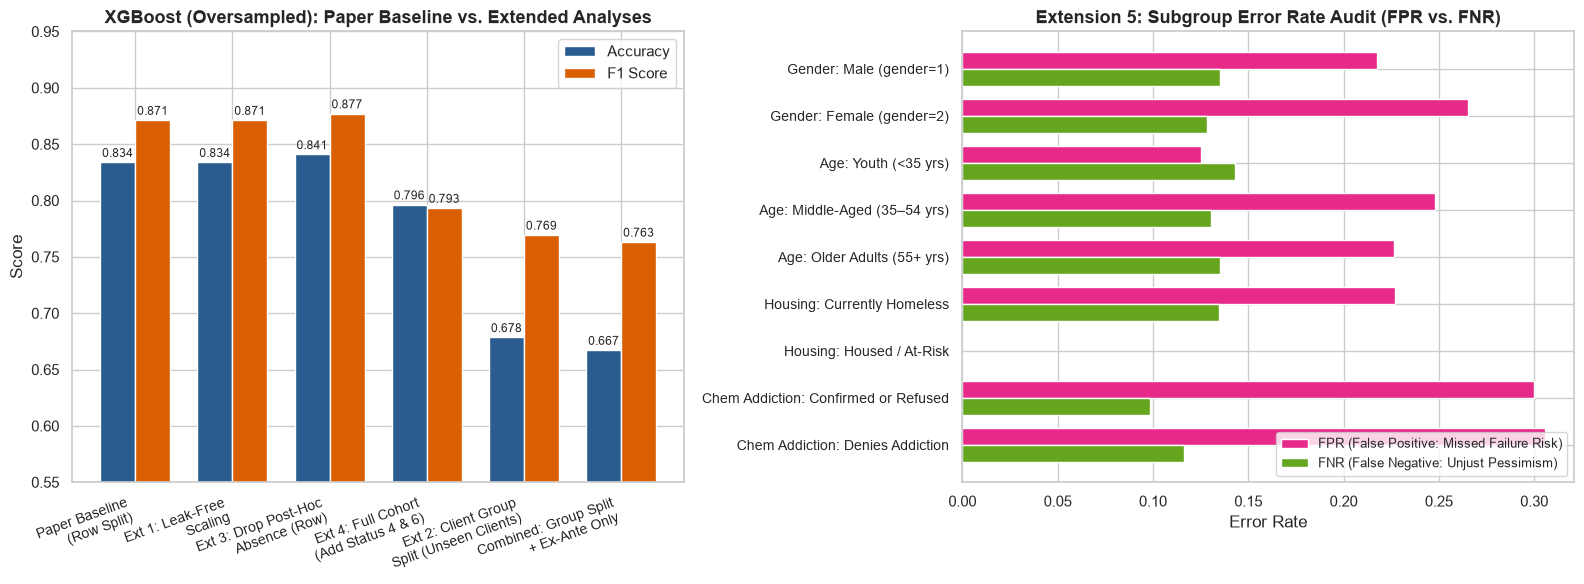

In [12]:
# Plot 1: Side-by-Side Comparison Across Experimental Settings
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

labels_short = [
    'Paper Baseline\n(Row Split)',
    'Ext 1: Leak-Free\nScaling',
    'Ext 3: Drop Post-Hoc\nAbsence (Row)',
    'Ext 4: Full Cohort\n(Add Status 4 & 6)',
    'Ext 2: Client Group\nSplit (Unseen Clients)',
    'Combined: Group Split\n+ Ex-Ante Only'
]
xgb_accs = [
    master_summary.iloc[0]['XGBoost (OS) Acc'],
    master_summary.iloc[1]['XGBoost (OS) Acc'],
    master_summary.iloc[3]['XGBoost (OS) Acc'],
    master_summary.iloc[4]['XGBoost (OS) Acc'],
    master_summary.iloc[2]['XGBoost (OS) Acc'],
    master_summary.iloc[5]['XGBoost (OS) Acc'],
]
xgb_f1s = [
    master_summary.iloc[0]['XGBoost (OS) F1'],
    master_summary.iloc[1]['XGBoost (OS) F1'],
    master_summary.iloc[3]['XGBoost (OS) F1'],
    master_summary.iloc[4]['XGBoost (OS) F1'],
    master_summary.iloc[2]['XGBoost (OS) F1'],
    master_summary.iloc[5]['XGBoost (OS) F1'],
]

x_pos = np.arange(len(labels_short))
width = 0.36
rects1 = axes[0].bar(x_pos - width/2, xgb_accs, width, label='Accuracy', color='#2b5c8f')
rects2 = axes[0].bar(x_pos + width/2, xgb_f1s,  width, label='F1 Score', color='#d95f02')
axes[0].set_ylabel('Score', fontsize=12)
axes[0].set_title('XGBoost (Oversampled): Paper Baseline vs. Extended Analyses', fontsize=13, fontweight='bold')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(labels_short, rotation=20, ha='right', fontsize=10)
axes[0].set_ylim(0.55, 0.95)
axes[0].legend()
for r in rects1:
    axes[0].annotate(f"{r.get_height():.3f}", (r.get_x() + r.get_width()/2, r.get_height()),
                     ha='center', va='bottom', fontsize=8.5, xytext=(0, 2), textcoords='offset points')
for r in rects2:
    axes[0].annotate(f"{r.get_height():.3f}", (r.get_x() + r.get_width()/2, r.get_height()),
                     ha='center', va='bottom', fontsize=8.5, xytext=(0, 2), textcoords='offset points')

# Plot 2: Subgroup Error Rate Disparities (FPR vs FNR)
sg_plot_df = ext5_df.iloc[1:].copy() # Exclude overall row
y_pos = np.arange(len(sg_plot_df))
axes[1].barh(y_pos - width/2, sg_plot_df['FPR (Missed Risk)'], width, label='FPR (False Positive: Missed Failure Risk)', color='#e7298a')
axes[1].barh(y_pos + width/2, sg_plot_df['FNR (Unjust Pessimism)'], width, label='FNR (False Negative: Unjust Pessimism)', color='#66a61e')
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(sg_plot_df['Subgroup'], fontsize=10)
axes[1].invert_yaxis()
axes[1].set_xlabel('Error Rate', fontsize=12)
axes[1].set_title('Extension 5: Subgroup Error Rate Audit (FPR vs. FNR)', fontsize=13, fontweight='bold')
axes[1].legend(loc='lower right', fontsize=9.5)

plt.tight_layout()
plt.show()
